In [1]:

from google.cloud import bigquery
import pandas as pd

PROJECT_ID = "polished-trail-511415-r4"

client = bigquery.Client(project=PROJECT_ID)

query = """
SELECT
    case_id,
    activity,
    timestamp,
    department,
    shift,
    patient_category,
    resource
FROM `polished-trail-511415-r4.careflow.event_log`
ORDER BY case_id, timestamp
"""

df = client.query(query).to_dataframe()

print("Total events:", len(df))
print("Unique cases:", df["case_id"].nunique())
print("Activities:", df["activity"].nunique())
display(df.head())


C:\Users\suraj\ad\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Total events: 27962
Unique cases: 5000
Activities: 9


,case_id,activity,timestamp,department,shift,patient_category,resource
0,P00001,Registration,2026-10-07 20:32:41+00:00,Emergency,Afternoon,Adult,Registration_02
1,P00001,Triage,2026-10-07 20:42:41+00:00,Emergency,Afternoon,Adult,Nurse_03
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Emergency,Afternoon,Adult,LabTech_02
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Emergency,Afternoon,Adult,Nurse_02
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Emergency,Afternoon,Adult,Doctor_02


In [2]:

import pm4py

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

event_log = pm4py.format_dataframe(
    df,
    case_id="case_id",
    activity_key="activity",
    timestamp_key="timestamp"
)

print("PM4Py event log created successfully")




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




PM4Py event log created successfully


In [4]:

import pm4py

# Discover the process tree from the event log
process_tree = pm4py.discover_process_tree_inductive(event_log)

# Convert the process tree into a Petri net
net, initial_marking, final_marking = pm4py.convert_to_petri_net(
    process_tree
)

print("Process tree discovered and converted successfully!")


Process tree discovered and converted successfully!


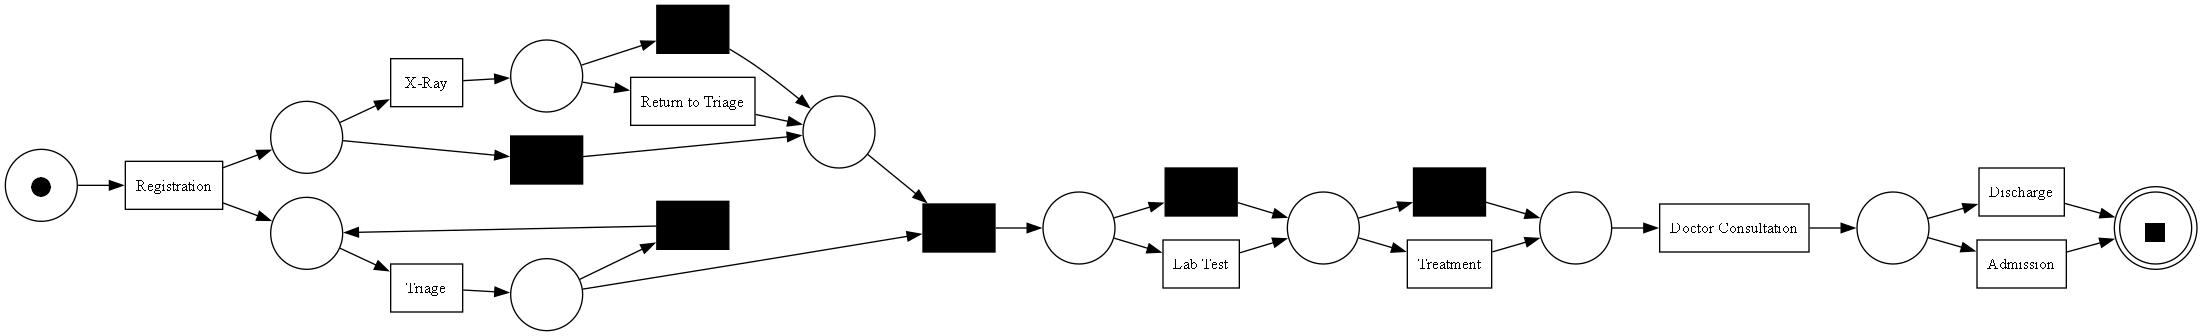

Process map saved successfully!


In [5]:

from pm4py.visualization.petri_net import visualizer as pn_visualizer

gviz = pn_visualizer.apply(
    net,
    initial_marking,
    final_marking
)

pn_visualizer.save(
    gviz,
    "careflow_as_is_process_map.png"
)

pn_visualizer.view(gviz)

print("Process map saved successfully!")


In [6]:
import pm4py

print("PM4Py version:", pm4py.__version__)
print("Event log type:", type(event_log))
print("Process tree type:", type(process_tree))

PM4Py version: 2.7.23.9
Event log type: <class 'pandas.DataFrame'>
Process tree type: <class 'pm4py.objects.process_tree.obj.ProcessTree'>
